# Exploring Players

Biographical and draft information for each prospect in the combine data. All data is taken from [here](https://www.kaggle.com/competitions/nfl-big-data-bowl-2027/data). The `nfl_id` column links this table to every other file.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

## players.csv

In [2]:
df = pd.read_csv("../data/players.csv")
df.head().style.format(precision=2).set_caption("First Rows")

,nfl_id,display_name,draft_year,nfl_position,birth_date,college_name,college_conference,draft_round,draft_pick_within_round,draft_overall_pick
0,55867,Will Anderson,2023,DE,2001-09-02,Alabama,Southeastern Conference,1.00,3.00,3.00
1,55870,Paris Johnson,2023,T,2001-07-31,Ohio State,Big Ten Conference,1.00,6.00,6.00
2,55874,Darnell Wright,2023,T,2001-08-10,Tennessee,Southeastern Conference,1.00,10.00,10.00
3,55875,Peter Skoronski,2023,G,2001-07-31,Northwestern,Big Ten Conference,1.00,11.00,11.00
4,55877,Lukas Van Ness,2023,DE,2001-07-06,Iowa,Big Ten Conference,1.00,13.00,13.00


In [3]:
print(len(df)) # total number of players in dataset
print(df.isna().sum())

510
nfl_id                       0
display_name                 0
draft_year                   0
nfl_position                 0
birth_date                   0
college_name                 0
college_conference           0
draft_round                127
draft_pick_within_round    127
draft_overall_pick         127
dtype: int64


In [4]:
positions = pd.read_csv("../data/combine_results.csv", usecols=["nfl_id", "combine_position"])
df = df.merge(positions, on="nfl_id", how="left")

masks = {
    "TE": df["combine_position"] == "TE",
    "DB": df["combine_position"] == "DB",
    "WR": df["combine_position"] == "WR",
    "DL": df["combine_position"] == "DL",
    "OL": df["combine_position"] == "OL",
}

### Positions

`nfl_position` is the player's NFL position, which is finer grained than the combine position groups.

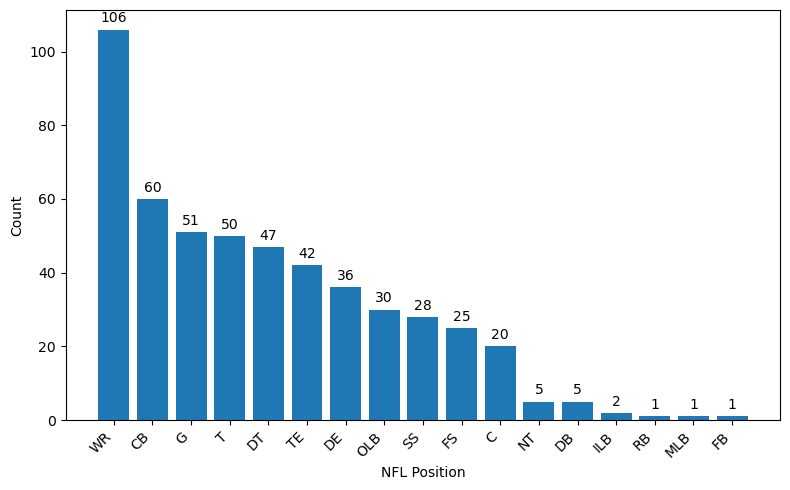

In [5]:
counts = df["nfl_position"].value_counts()

fig, ax = plt.subplots(figsize=(8,5))
bars = ax.bar(counts.index.astype(str), counts.values)
ax.bar_label(bars, padding=3)

ax.set_xlabel("NFL Position")
ax.set_ylabel("Count")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [6]:
pd.crosstab(df["nfl_position"], df["combine_position"])

combine_position,DB,DL,OL,TE,WR
nfl_position,,,,,
C,0,0,20,0,0
CB,60,0,0,0,0
DB,5,0,0,0,0
DE,0,36,0,0,0
DT,0,47,0,0,0
FB,0,0,0,1,0
FS,25,0,0,0,0
G,0,0,51,0,0
ILB,2,0,0,0,0


### Draft

In [7]:
df["drafted"] = df["draft_round"].notna()
print(df["drafted"].value_counts())
print(df.groupby("combine_position")["drafted"].mean().round(2)) # fraction drafted per position

drafted
True     383
False    127
Name: count, dtype: int64
combine_position
DB    0.80
DL    0.75
OL    0.74
TE    0.74
WR    0.72
Name: drafted, dtype: float64


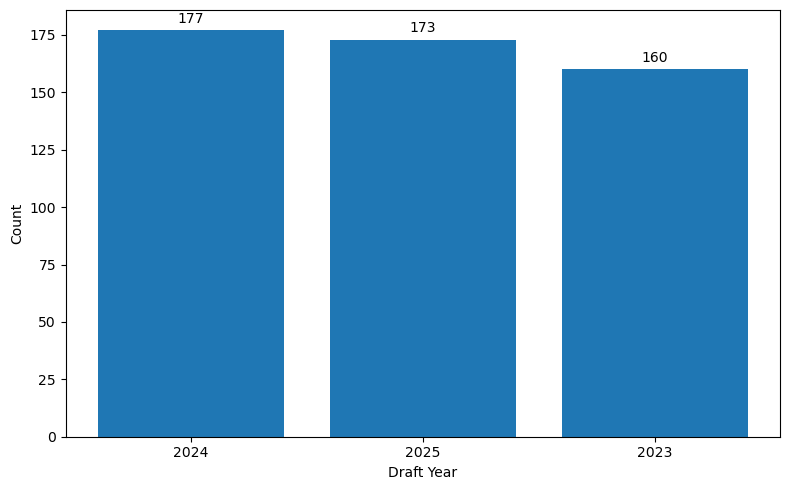

In [8]:
counts = df["draft_year"].value_counts()

fig, ax = plt.subplots(figsize=(8,5))
bars = ax.bar(counts.index.astype(str), counts.values)
ax.bar_label(bars, padding=3)

ax.set_xlabel("Draft Year")
ax.set_ylabel("Count")
plt.tight_layout()
plt.show()

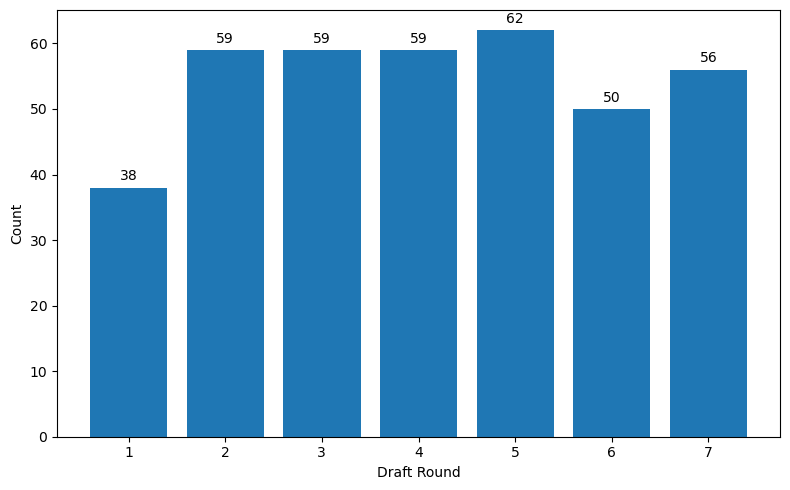

In [9]:
counts = df["draft_round"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8,5))
bars = ax.bar(counts.index.astype(int).astype(str), counts.values)
ax.bar_label(bars, padding=3)

ax.set_xlabel("Draft Round")
ax.set_ylabel("Count")
plt.tight_layout()
plt.show()

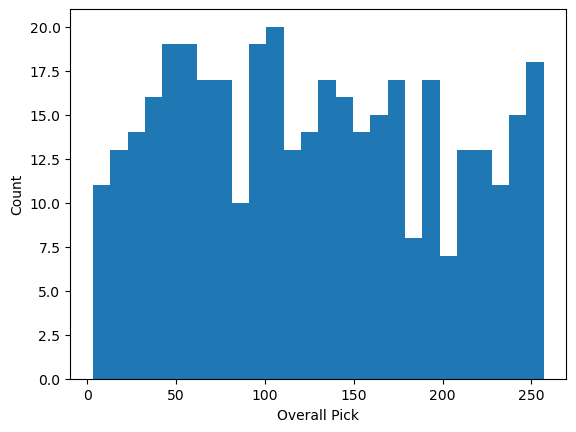

In [10]:
plt.hist(df["draft_overall_pick"].dropna(), bins=26)
plt.xlabel("Overall Pick")
plt.ylabel("Count");

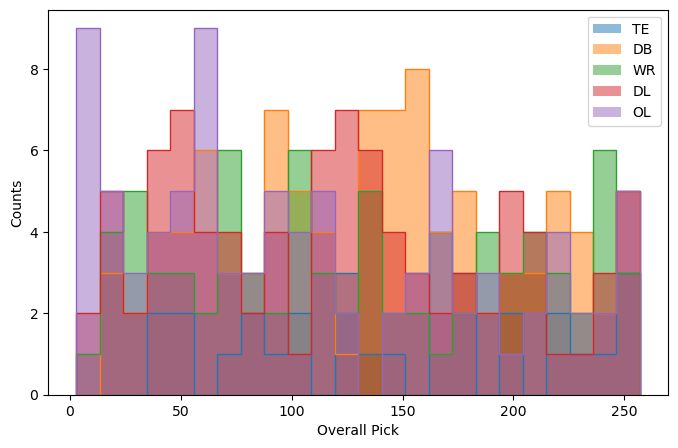

In [11]:
bins = np.linspace(df["draft_overall_pick"].min(), df["draft_overall_pick"].max(), 25)

fig, ax = plt.subplots(figsize=(8,5))
for i, (name, m) in enumerate(masks.items()):
    color = f"C{i}"
    ax.hist(df.loc[m, "draft_overall_pick"], bins=bins, histtype="step", color=color)
    ax.hist(df.loc[m, "draft_overall_pick"], bins=bins, histtype="stepfilled", label=name, color=color, alpha=0.5)

ax.set_xlabel("Overall Pick")
ax.set_ylabel("Counts")
ax.legend()
plt.show()

### Age

Age on April 25th of the draft year (roughly draft day).

In [12]:
draft_day = pd.to_datetime(df["draft_year"].astype(str) + "-04-25")
df["draft_age"] = (draft_day - pd.to_datetime(df["birth_date"])).dt.days / 365.25

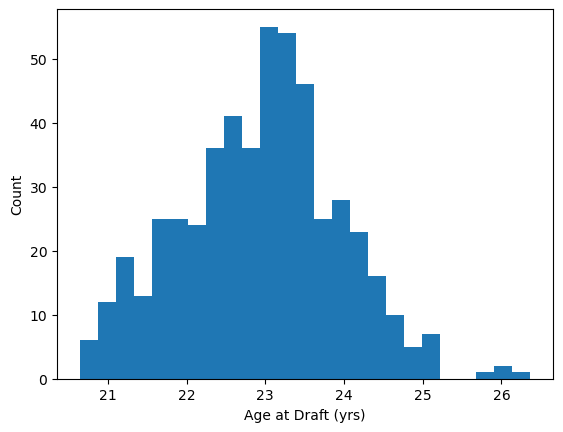

In [13]:
plt.hist(df["draft_age"].dropna(), bins=25)
plt.xlabel("Age at Draft (yrs)")
plt.ylabel("Count");

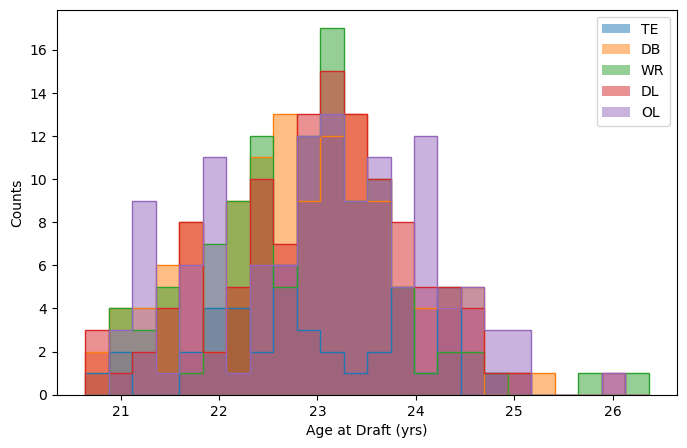

In [14]:
bins = np.linspace(df["draft_age"].min(), df["draft_age"].max(), 25)

fig, ax = plt.subplots(figsize=(8,5))
for i, (name, m) in enumerate(masks.items()):
    color = f"C{i}"
    ax.hist(df.loc[m, "draft_age"], bins=bins, histtype="step", color=color)
    ax.hist(df.loc[m, "draft_age"], bins=bins, histtype="stepfilled", label=name, color=color, alpha=0.5)

ax.set_xlabel("Age at Draft (yrs)")
ax.set_ylabel("Counts")
ax.legend()
plt.show()

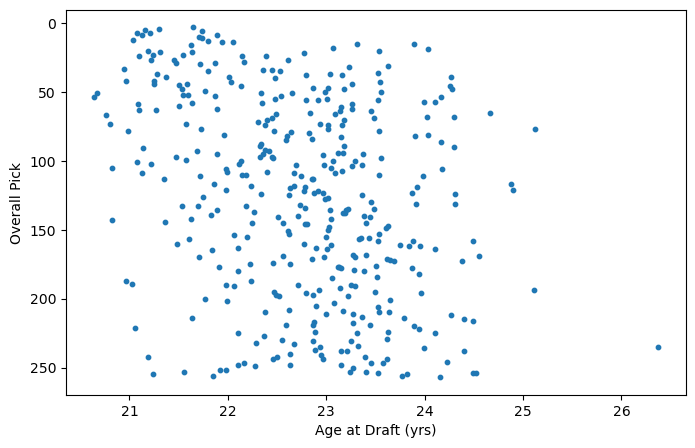

In [15]:
fig, ax = plt.subplots(figsize=(8,5))
ax.scatter(df["draft_age"], df["draft_overall_pick"], s=10)
ax.set_xlabel("Age at Draft (yrs)")
ax.set_ylabel("Overall Pick")
ax.invert_yaxis()
plt.show()

### College

In [16]:
print(df["college_name"].nunique()) # number of distinct colleges

112


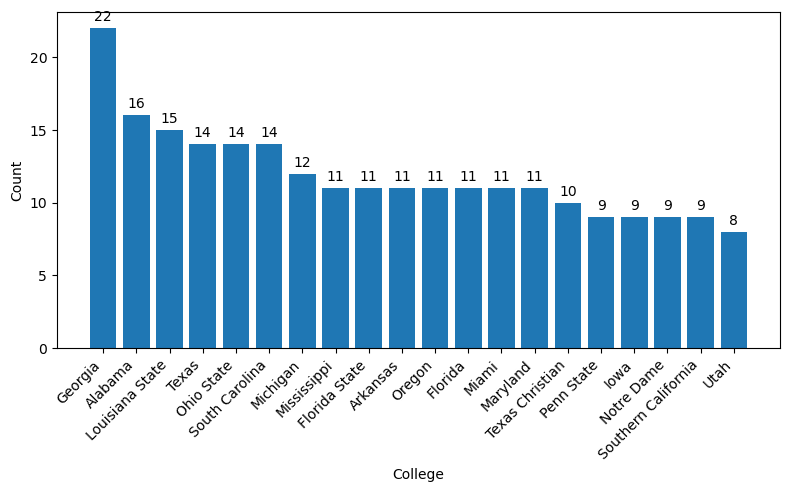

In [17]:
counts = df["college_name"].value_counts().head(20)

fig, ax = plt.subplots(figsize=(8,5))
bars = ax.bar(counts.index.astype(str), counts.values)
ax.bar_label(bars, padding=3)

ax.set_xlabel("College")
ax.set_ylabel("Count")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

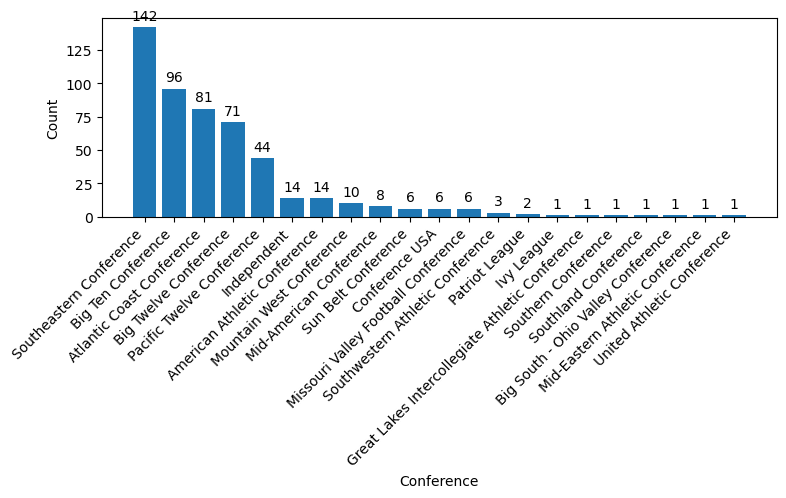

In [18]:
counts = df["college_conference"].value_counts()

fig, ax = plt.subplots(figsize=(8,5))
bars = ax.bar(counts.index.astype(str), counts.values)
ax.bar_label(bars, padding=3)

ax.set_xlabel("Conference")
ax.set_ylabel("Count")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()